# Sleep Staging — 02: Preprocessing de señales

**Objetivo de este notebook:** aplicar de forma reproducible las decisiones metodológicas definidas en la NB1 y generar un dataset procesado, trazable y reutilizable tanto para feature engineering como para deep learning.

> **Principio de diseño:** NB1 define el screening exploratorio y las exclusiones a nivel sujeto; NB2 reproduce ese screening exactamente y documenta de forma explícita cualquier decisión operativa adicional necesaria para generar el dataset final.

---

### Flujo del pipeline

```text
EDF + anotaciones
        │
        ▼
selección de 7 canales EEG/EOG/EMG
        │
        ▼
alineación exacta usando Recording onset de cada epoch
        │
        ├──────────────► screening QC de NB1 sobre señal cruda alineada
        │                  limpio / sospechoso
        │                         │
        │                         ▼
        │                  acción NB2
        │                  ok / review / discard
        │
        ▼
filtrado continuo 0.5–35 Hz
        │
        ▼
resampling 256 → 100 Hz
        │
        ▼
extracción de epochs procesados con los mismos onsets
        │
        ▼
conservar ok + review / eliminar discard
        │
        ▼
guardar señal procesada en µV + metadata + estadísticas de normalización
```

Los sujetos `SN032` y `SN033` se excluyen **a nivel sujeto antes de generar el dataset final**, porque la NB1 los identificó como registros globalmente problemáticos por clipping/saturación extensa y multicanal. Esta decisión es previa al modelado.

`SN020`, en cambio, se conserva, coherentemente con la conclusión de NB1.


## 0. Setup

In [ ]:
import os
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne

# Reducir mensajes y warnings de MNE
mne.set_log_level("WARNING")
warnings.filterwarnings("ignore", category=RuntimeWarning)

# Rutas
DATA_PATH = "../data/recordings"
OUTPUT_PATH = "../data/processed"
os.makedirs(OUTPUT_PATH, exist_ok=True)

# ============================================================
# Constantes compartidas con la NB1 final
# ============================================================
EPOCH_DURATION_S = 30
SECONDS_PER_HOUR = 3600
EPOCH_DURATION_H = EPOCH_DURATION_S / SECONDS_PER_HOUR

# Screening exploratorio de QC definido en NB1
AMPLITUDE_THRESHOLD_UV = 500
FLAT_DURATION_S = 1.0
REVIEW_THRESHOLD_PCT = 70

# Sujetos excluidos a priori por QC global observado en NB1.
# La exclusión NO depende del desempeño de ningún modelo.
EXCLUDED_SUBJECTS = {
    "SN032": {
        "status": "excluded_subject_qc",
        "reason": (
            "problema sistemático de calidad identificado en NB1: "
            "clipping/saturación extensa y multicanal en torno a ±800 µV"
        ),
        "pct_suspicious_nb1": 95.5,
    },
    "SN033": {
        "status": "excluded_subject_qc",
        "reason": (
            "problema sistemático de calidad identificado en NB1: "
            "clipping/saturación extensa y multicanal en torno a ±800 µV"
        ),
        "pct_suspicious_nb1": 81.0,
    },
}

# ============================================================
# Parámetros del pipeline
# ============================================================
PARAMS = {
    # Canales utilizados
    "eeg_channels": [
        "EEG F4-M1",
        "EEG C4-M1",
        "EEG O2-M1",
        "EEG C3-M2",
    ],
    "eog_channels": [
        "EOG E1-M2",
        "EOG E2-M2",
    ],
    "emg_channels": [
        "EMG chin",
    ],

    # Frecuencia de muestreo
    "target_sfreq": 100,

    # Filtrado común del baseline
    "bandpass_low": 0.5,
    "bandpass_high": 35.0,

    # Segmentación
    "epoch_duration": EPOCH_DURATION_S,

    # --------------------------------------------------------
    # QC base: idéntico al screening de NB1
    # --------------------------------------------------------
    "amplitude_review_uv": AMPLITUDE_THRESHOLD_UV,
    "flat_review_seconds": FLAT_DURATION_S,

    # --------------------------------------------------------
    # Política conservadora de descarte de NB2.
    #
    # La literatura reciente basada en U-Sleep marca como unknown
    # epochs con >50% de flatline. En este proyecto se adapta esa
    # idea de forma aún más conservadora: el descarte automático
    # se aplica solo si TODOS los EEG seleccionados presentan un
    # flatline continuo que ocupa >50% del epoch.
    #
    # Una anomalía de amplitud, por sí sola, NO causa descarte.
    #
    # Invariante exigido:
    #     suspicious_NB1 == review_NB2 OR discard_NB2
    # --------------------------------------------------------
    "severe_flat_fraction_discard": 0.50,
    "require_all_eeg_channels_flat_for_discard": True,
}

# Codificación numérica estable utilizada por el pipeline y notebooks posteriores.
# NB1 usa STAGE_TO_Y principalmente como posición vertical del hypnogram;
STAGE_MAP = {
    "Sleep stage W": 0,
    "Sleep stage N1": 1,
    "Sleep stage N2": 2,
    "Sleep stage N3": 3,
    "Sleep stage R": 4,
}

STAGE_SHORT_MAP = {
    0: "W",
    1: "N1",
    2: "N2",
    3: "N3",
    4: "REM",
}
STAGE_ORDER = ["W", "N1", "N2", "N3", "REM"]

print("Parámetros del pipeline:")
for key, value in PARAMS.items():
    print(f"  {key}: {value}")

print("\nSujetos excluidos por QC global de NB1:")
for subject_id, info in EXCLUDED_SUBJECTS.items():
    print(
        f"  {subject_id} → {info['status']} "
        f"(epochs sospechosos NB1: {info['pct_suspicious_nb1']:.1f}%)"
    )


Parámetros del pipeline:
  eeg_channels: ['EEG F4-M1', 'EEG C4-M1', 'EEG O2-M1', 'EEG C3-M2']
  eog_channels: ['EOG E1-M2', 'EOG E2-M2']
  emg_channels: ['EMG chin']
  target_sfreq: 100
  bandpass_low: 0.5
  bandpass_high: 35.0
  epoch_duration: 30
  amplitude_review_uv: 500
  flat_review_seconds: 1.0
  severe_flat_fraction_discard: 0.5
  require_all_eeg_channels_flat_for_discard: True

Sujetos excluidos por QC global de NB1:
  SN032 → excluded_subject_qc (epochs sospechosos NB1: 95.5%)
  SN033 → excluded_subject_qc (epochs sospechosos NB1: 81.0%)


---
## 1. Selección de canales

Se conservan los siete canales definidos en NB1: cuatro EEG, dos EOG y un EMG de mentón. El objetivo es mantener una representación multimodal directamente vinculada con la caracterización de etapas del sueño.

El ECG y otros canales auxiliares no se incluyen en la configuración principal de este trabajo. Esto no implica que carezcan de información potencial; simplemente quedan fuera del alcance del pipeline multimodal EEG/EOG/EMG definido para el baseline y las primeras arquitecturas de deep learning.


In [37]:
def load_and_select_channels(edf_path, params):
    """
    Carga un archivo EDF, selecciona los canales utilizados
    y asigna correctamente sus tipos en MNE.
    """

    raw = mne.io.read_raw_edf(
        edf_path,
        preload=True,
        verbose=False
    )

    # Canales utilizados por el pipeline
    channels_to_keep = (
        params["eeg_channels"]
        + params["eog_channels"]
        + params["emg_channels"]
    )

    # Verificar que estén todos disponibles
    missing = [
        ch for ch in channels_to_keep
        if ch not in raw.ch_names
    ]

    if missing:
        raise ValueError(
            f"Canales faltantes en {os.path.basename(edf_path)}: {missing}"
        )

    # Seleccionar canales
    raw.pick(channels_to_keep)

    # Asignar tipos
    type_map = {
        **{ch: "eeg" for ch in params["eeg_channels"]},
        **{ch: "eog" for ch in params["eog_channels"]},
        **{ch: "emg" for ch in params["emg_channels"]},
    }

    raw.set_channel_types(type_map)

    return raw

In [38]:
# Probar con un sujeto de ejemplo
sample_path = os.path.join(DATA_PATH, "SN001.edf")
raw = load_and_select_channels(sample_path, PARAMS)

print(f"Canales seleccionados ({len(raw.ch_names)}):")

for channel, channel_type in zip(
    raw.ch_names,
    raw.get_channel_types()
):
    print(f"  {channel} → {channel_type}")

print(f"Duración: {raw.duration / 3600:.2f} h")

Canales seleccionados (7):
  EEG F4-M1 → eeg
  EEG C4-M1 → eeg
  EEG O2-M1 → eeg
  EEG C3-M2 → eeg
  EOG E1-M2 → eog
  EOG E2-M2 → eog
  EMG chin → emg
Duración: 7.12 h


---
## 2. Carga de labels y alineación temporal

Cada epoch se extrae utilizando **su propio `Recording onset`**. No se usa únicamente el primer onset ni se asume que toda la secuencia es perfectamente continua.

Esta decisión permite conservar la alineación correcta incluso si existieran gaps, epochs faltantes o irregularidades en las anotaciones. Además, el pipeline guarda el onset y el índice de origen de cada epoch para mantener trazabilidad completa.


In [39]:
def load_labels(txt_path, stage_map):
    """
    Lee el archivo de anotaciones y conserva únicamente sleep stages.

    Replica la validación temporal de NB1:
    - limpia nombres y anotaciones;
    - conserva únicamente filas "Sleep stage";
    - exige Duration = 30 s;
    - preserva índices de trazabilidad.
    """
    df = pd.read_csv(txt_path)
    df.columns = df.columns.str.strip()

    required_columns = {"Annotation", "Duration"}
    missing_columns = required_columns - set(df.columns)
    # Verificación de columnas requeridas
    # Si faltan columnas, se lanza un error con detalle
    if missing_columns:
        raise ValueError(
            f"Columnas faltantes en {os.path.basename(txt_path)}: "
            f"{sorted(missing_columns)}"
        )

    # Limpiar anotaciones
    # Se eliminan espacios en blanco y se asegura que sean strings
    df["Annotation"] = df["Annotation"].astype(str).str.strip()

    # Conservar solo sleep stages preservando la fila original
    sleep_mask = df["Annotation"].str.startswith("Sleep stage", na=False)
    df = df.loc[sleep_mask].copy()
    # Preservar índice original y posición en la secuencia de sleep stages
    df["source_annotation_index"] = df.index.astype(np.int64)
    df = df.reset_index(drop=True)
    df["source_epoch_index"] = np.arange(len(df), dtype=np.int64)

    # Misma validación de duración que NB1
    # Se convierte a numérico y se verifica que las duraciones sean aprox 30 s.
    durations = pd.to_numeric(df["Duration"], errors="coerce")
    invalid_duration = (
        durations.isna()
        | ~np.isclose(durations.to_numpy(dtype=float), EPOCH_DURATION_S)
    )

    if np.any(invalid_duration):
        raise ValueError(
            f"Se encontraron sleep stages con duración distinta de "
            f"{EPOCH_DURATION_S} s en {os.path.basename(txt_path)}"
        )

    # Convertir stages a enteros
    df["label"] = df["Annotation"].map(stage_map)

    unknown = int(df["label"].isna().sum())
    if unknown > 0:
        print(f"  ⚠️ {unknown} epochs con stage desconocido — serán descartados")
        df = df.dropna(subset=["label"]).copy()

    df["label"] = df["label"].astype(np.int64)
    return df


def get_recording_onset_column(labels_df):
    """Identifica de forma explícita la columna de Recording onset."""

    # Primero se busca coincidencia exacta (ignorando mayúsculas y espacios)
    exact = [
        c for c in labels_df.columns
        if c.strip().lower() == "recording onset"
    ]

    if exact:
        return exact[0]

    # Si no hay coincidencia exacta, se buscan columnas con "onset"
    candidates = [
        c for c in labels_df.columns
        if "onset" in c.lower()
    ]

    # Si hay más de una candidata, se lanza un error con detalle
    if len(candidates) != 1:
        raise ValueError(
            "No fue posible identificar de forma unívoca la columna "
            f"Recording onset. Candidatas: {candidates}"
        )

    return candidates[0]


def align_epochs_and_labels(
    data_raw,
    labels_df,
    sfreq,
    epoch_duration=EPOCH_DURATION_S
):
    """
    Extrae cada epoch desde la señal utilizando el Recording onset real
    de la fila correspondiente.

    No supone continuidad entre anotaciones.

    Returns
    -------
    X : np.ndarray
        (n_epochs_aligned, n_channels, n_samples_per_epoch)
    y : np.ndarray
        Labels alineados.
    source_epoch_index : np.ndarray
        Índice del epoch dentro de la secuencia de sleep stages original.
    recording_onset_s : np.ndarray
        Onset real, en segundos, de cada epoch alineado.
    """
    epoch_samples = int(round(epoch_duration * sfreq))
    onset_col = get_recording_onset_column(labels_df)

    # Extraer del DataFrame únicamente las columnas necesarias
    # y convertirlas a arrays NumPy para el procesamiento numérico
    onsets = pd.to_numeric(
        labels_df[onset_col],
        errors="coerce"
    ).to_numpy(dtype=float)

    labels = labels_df["label"].to_numpy(dtype=np.int64)

    source_epoch_indices = labels_df[
        "source_epoch_index"
    ].to_numpy(dtype=np.int64)

    # Identificar onsets válidos (numéricos y no negativos)
    valid_onsets = np.isfinite(onsets) & (onsets >= 0)

    # Calcular índices de muestra para todos los epochs válidos
    # Se define el inicio y fin del epoch en muestras
    start_samples = np.zeros(len(onsets), dtype=np.int64)

    start_samples[valid_onsets] = np.rint(
        onsets[valid_onsets] * sfreq
    ).astype(np.int64)

    end_samples = start_samples + epoch_samples

    epochs_list = []        # Señal
    labels_list = []        # Labels de Stages
    source_indices = []     # Número de epoch en la secuencia original
    onsets_s = []           # Onset real en segundos de cada epoch alineado

    skipped_rows = []       # Filas que no pudieron alinearse

    # Recorrer los arrays NumPy únicamente para extraer
    # los segmentos correspondientes de la señal
    for (
        onset_s,
        label,
        source_idx,
        start_sample,
        end_sample,
        onset_is_valid,
    ) in zip(
        onsets,
        labels,
        source_epoch_indices,
        start_samples,
        end_samples,
        valid_onsets,
    ):

        # Descartar epochs con onset inválido (NaN o negativo)
        if not onset_is_valid:
            skipped_rows.append((source_idx, "onset inválido"))
            continue

        # Verificar que el epoch se encuentre dentro del rango disponible
        # de la señal registrada
        if end_sample > data_raw.shape[1]:
            skipped_rows.append(
                (source_idx, "fuera del rango de la señal")
            )
            continue

        # Extraer el epoch de la señal cruda
        # Se utilizan los 7 canales y la duración de muestra correspondiente a 30 s
        epoch = data_raw[:, start_sample:end_sample]

        # Verificar que el epoch tenga la duración (cantidad de muestras) esperada
        if epoch.shape[1] != epoch_samples:
            skipped_rows.append((source_idx, "duración incompleta"))
            continue

        # Agregar el epoch y la información correspondiente a las listas
        epochs_list.append(epoch)
        labels_list.append(label)
        source_indices.append(source_idx)
        onsets_s.append(onset_s)

    if skipped_rows:
        print(f"  ⚠️ {len(skipped_rows)} epochs no pudieron alinearse")

        reason_counts = pd.Series(
            [reason for _, reason in skipped_rows]
        ).value_counts()

        for reason, count in reason_counts.items():
            print(f"     {reason}: {count}")

    if not epochs_list:
        raise ValueError("No se pudo alinear ningún epoch con la señal")

    # Convertir listas a arrays NumPy
    X = np.stack(epochs_list).astype(
        data_raw.dtype,
        copy=False
    )

    y = np.asarray(
        labels_list,
        dtype=np.int64
    )

    source_epoch_index = np.asarray(
        source_indices,
        dtype=np.int64
    )

    recording_onset_s = np.asarray(
        onsets_s,
        dtype=np.float64
    )

    return X, y, source_epoch_index, recording_onset_s


# Verificación con un sujeto de ejemplo sobre señal cruda
example_labels_path = os.path.join(DATA_PATH, "SN001_sleepscoring.txt")
labels_df_example = load_labels(example_labels_path, STAGE_MAP)

X_raw_example, y_raw_example, source_idx_example, onsets_example = (
    align_epochs_and_labels(
        data_raw=raw.get_data(),
        labels_df=labels_df_example,
        sfreq=raw.info["sfreq"],
        epoch_duration=PARAMS["epoch_duration"],
    )
)

print(f"X crudo alineado: {X_raw_example.shape}")
print(f"y:                 {y_raw_example.shape}")
print(f"Primer onset:       {onsets_example[0]:.2f} s")
print(f"Último onset:       {onsets_example[-1]:.2f} s")

onset_diffs = np.diff(onsets_example)
irregular = ~np.isclose(onset_diffs, PARAMS["epoch_duration"], atol=1e-6)
print(f"Saltos distintos de 30 s: {int(irregular.sum())}")


X crudo alineado: (854, 7, 7680)
y:                 (854,)
Primer onset:       0.00 s
Último onset:       25590.00 s
Saltos distintos de 30 s: 0


### Trazabilidad de la alineación

La relación fundamental queda expresada por:

```text
source_epoch_index[i]
recording_onset_s[i]
y[i]
X[i]
```

`recording_onset_s` indica el instante real de inicio del epoch en el EDF y `source_epoch_index` permite rastrear su posición en la secuencia original de etapas anotadas.

La extracción utiliza:

```text
start_sample = round(recording_onset_s × sfreq)
end_sample   = start_sample + 30 s × sfreq
```

Por lo tanto, si hubiera un gap entre dos anotaciones, el pipeline no desplaza artificialmente los epochs siguientes: cada uno vuelve a localizarse por su propio onset.


---
## 3. Control de calidad por epoch

El QC se aplica sobre **epochs crudos ya alineados con sus labels**, antes del filtrado y del resampling. De esta manera, el estado de calidad corresponde exactamente al fragmento temporal y a la etapa del sueño anotada.

### 3.1 Screening sensible: consistente con NB1

La NB1 final utiliza un screening exploratorio sobre EEG. Un epoch se considera **sospechoso** si ocurre al menos una de estas dos condiciones:

- algún canal EEG presenta `|amplitud| > 500 µV`;
- algún canal EEG permanece exactamente plano durante al menos `1 s`.

Estos valores se utilizan como **banderas de revisión**, no como una afirmación de que el epoch sea necesariamente inválido. En particular, una excursión de amplitud elevada no causa descarte automático.

### 3.2 Política de descarte: pérdida severa de señal

Para evitar umbrales ad hoc de severidad (`1500 µV`, `5 s`, `1% de muestras`, etc.), NB2 adopta una política mucho más conservadora.

Un trabajo reciente basado en **U-Sleep** marca como `unknown` los epochs que contienen más de 50% de flatline. A partir de esa referencia se adopta el umbral temporal:

```text
flatline severo > 50% del epoch de 30 s
                 > 15 s
```

Como este proyecto dispone de **cuatro derivaciones EEG**, no se elimina un epoch por la falla de un único canal. Para reducir el riesgo de descartar información todavía utilizable, el descarte automático se restringe a un caso inequívoco de pérdida multicanal:

```text
discard = los 4 EEG presentan un flatline continuo > 50% del epoch
```

Si el problema afecta solo una parte de los EEG, el epoch queda como `review` y se conserva.

Por lo tanto:

```text
ok       → no activa el screening de NB1
review   → activa el screening, pero conserva información utilizable
discard  → pérdida severa y generalizada de EEG por flatline
```

Y se mantiene la invariante:

```text
suspicious_NB1 == review_NB2 ∪ discard_NB2
```

### 3.3 Justificación bibliográfica

Esta política sigue una filosofía conservadora basada en:

- **Vallat & Walker (2021), eLife, DOI 10.7554/eLife.70092**: YASA realiza sleep staging sin remover artefactos previamente; utiliza PSG real y heterogénea, lo que respalda no eliminar automáticamente epochs por anomalías moderadas de amplitud.
- **Sommerauer et al. (2026), npj Digital Medicine, DOI 10.1038/s41746-026-02946-2**: en un pipeline basado en U-Sleep, los epochs con más de 50% de flatline se etiquetan como `unknown`, aportando un criterio publicado para pérdida severa de señal.

La exigencia de que los **cuatro EEG** estén severamente afectados es una adaptación conservadora específica de este proyecto, motivada por la redundancia multicanal disponible. No se presenta como un umbral clínico universal.


In [40]:
# ============================================================
# Funciones auxiliares de QC
# has_flat_segment() y check_epoch() replican la NB1 final.
# ============================================================

def has_flat_segment(signal, min_samples):
    """True si existe un tramo de al menos min_samples valores iguales."""

    repeated = np.diff(signal) == 0
    boundaries = np.r_[True, ~repeated, True]
    run_lengths = np.diff(np.flatnonzero(boundaries))

    return run_lengths.max() >= min_samples


def check_epoch(epoch_data_uv, channel_names, flat_samples):
    """Devuelve las razones por las que NB1 marca un epoch como sospechoso."""

    reasons = []

    for signal, channel in zip(epoch_data_uv, channel_names):

        if np.max(np.abs(signal)) > AMPLITUDE_THRESHOLD_UV:
            reasons.append(
                f"amplitud>{AMPLITUDE_THRESHOLD_UV}µV en {channel}"
            )

        if has_flat_segment(signal, flat_samples):
            reasons.append(
                f"segmento plano>={FLAT_DURATION_S:g}s en {channel}"
            )

    return reasons


def longest_flat_run_samples(signal):
    """Devuelve la longitud, en muestras, del tramo constante más largo."""
    if len(signal) == 0:
        return 0

    repeated = np.diff(signal) == 0
    boundaries = np.r_[True, ~repeated, True]
    run_lengths = np.diff(np.flatnonzero(boundaries))

    return int(run_lengths.max())


def longest_flat_fraction(signal):
    """Fracción del epoch ocupada por el tramo constante más largo."""
    if len(signal) == 0:
        return 0.0
    return longest_flat_run_samples(signal) / len(signal)


In [41]:
# ============================================================
# Evaluación detallada de calidad por epoch
# ============================================================

def evaluate_epoch_quality(
    data_epochs,
    sfreq,
    params,
    eeg_ch_indices,
    channel_names,
):
    """
    Evalúa la calidad de cada epoch utilizando únicamente canales EEG.

    Screening (NB1):
        amplitud > 500 µV OR flat >= 1 s  -> suspicious

    Acción (NB2):
        suspicious + flatline continuo >50% en TODOS los EEG -> discard
        suspicious en cualquier otro caso                    -> review
        no suspicious                                        -> ok

    Una amplitud elevada por sí sola no produce descarte automático.

    Returns
    -------
    discard_mask : np.ndarray[bool]
    review_mask : np.ndarray[bool]
    df_quality : pd.DataFrame
        Métricas, estado y motivos de QC para cada epoch alineado.
    """
    n_epochs = data_epochs.shape[0]

    discard_mask = np.zeros(n_epochs, dtype=bool)
    review_mask = np.zeros(n_epochs, dtype=bool)
    suspicious_nb1_mask = np.zeros(n_epochs, dtype=bool)
    # Guarda información detallada de QC para trazabilidad y análisis posterior
    quality_rows = []

    eeg_channel_names = [channel_names[idx] for idx in eeg_ch_indices]
    # Número de muestras correspondiente a 1 s de flatline
    flat_samples_nb1 = int(round(FLAT_DURATION_S * sfreq))
    # Fracción de flatline continuo que dispara descarte automático
    severe_fraction = float(params["severe_flat_fraction_discard"])
    n_eeg = len(eeg_ch_indices)

    if not params.get("require_all_eeg_channels_flat_for_discard", True):
        raise ValueError(
            "Esta versión del pipeline define discard solo ante flatline "
            "severo en todos los EEG seleccionados."
        )

    for epoch_idx in range(n_epochs):
        epoch_eeg_uv = data_epochs[epoch_idx, eeg_ch_indices, :] * 1e6

        # ----------------------------------------------------
        # Screening EXACTO de NB1
        # ----------------------------------------------------
        screening_reasons = check_epoch(
            epoch_eeg_uv,
            eeg_channel_names,
            flat_samples_nb1,
        )

        # Se marca como suspicious si hay alguna razón de screening
        is_suspicious_nb1 = bool(screening_reasons)
        suspicious_nb1_mask[epoch_idx] = is_suspicious_nb1

        # ----------------------------------------------------
        # Métricas por canal para trazabilidad
        # ----------------------------------------------------
        channel_metrics = []

        for signal_uv, channel in zip(epoch_eeg_uv, eeg_channel_names):
            max_abs_uv = float(np.max(np.abs(signal_uv)))
            flat_samples = longest_flat_run_samples(signal_uv)
            flat_seconds = flat_samples / sfreq
            flat_fraction = flat_samples / len(signal_uv)

            # Guardar métricas por canal para trazabilidad
            # Se calculan métricas de amplitud y flatline para cada canal EEG
            channel_metrics.append({
                "channel": channel,
                "max_abs_uv": max_abs_uv,
                "flat_samples": int(flat_samples),
                "flat_seconds": float(flat_seconds),
                "flat_fraction": float(flat_fraction),
            })

        max_abs_uv = max(m["max_abs_uv"] for m in channel_metrics)
        max_flat_seconds = max(m["flat_seconds"] for m in channel_metrics)
        max_flat_fraction = max(m["flat_fraction"] for m in channel_metrics)

        # Se analiza que flat fractions son flatlines severos (>50% del epoch)
        severe_flat_channels = [
            m["channel"]
            for m in channel_metrics
            if m["flat_fraction"] > severe_fraction
        ]
        n_severe_flat_channels = len(severe_flat_channels)

        # Descarte deliberadamente conservador:
        # todos los EEG deben presentar >50% de flatline continuo.
        is_severe_multichannel_flat = (
            n_severe_flat_channels == n_eeg
            and n_eeg > 0
        )

        if is_suspicious_nb1 and is_severe_multichannel_flat:
            status = "discard"
            discard_mask[epoch_idx] = True
            action_reasons = [
                f"flatline>{severe_fraction*100:.0f}% del epoch en todos los EEG"
            ]

        elif is_suspicious_nb1:
            status = "review"
            review_mask[epoch_idx] = True
            action_reasons = screening_reasons

        else:
            status = "ok"
            action_reasons = []

        quality_rows.append({
            "aligned_epoch_index": epoch_idx,
            "status": status,
            "nb1_suspicious_flag": bool(is_suspicious_nb1),
            "nb1_screening_reason": "; ".join(screening_reasons),
            "discard_flag": bool(discard_mask[epoch_idx]),
            "review_flag": bool(review_mask[epoch_idx]),
            "qc_reason": "; ".join(action_reasons),
            "max_abs_uv": round(max_abs_uv, 2),
            "max_flat_seconds": round(max_flat_seconds, 3),
            "max_flat_fraction": round(max_flat_fraction, 4),
            "n_severe_flat_channels": n_severe_flat_channels,
            "severe_flat_channels": ", ".join(severe_flat_channels),
        })

    # Invariante de sincronización NB1 ↔ NB2
    non_ok_mask = review_mask | discard_mask
    if not np.array_equal(suspicious_nb1_mask, non_ok_mask):
        raise RuntimeError(
            "Inconsistencia QC: suspicious_NB1 != review_NB2 ∪ discard_NB2"
        )

    df_quality = pd.DataFrame(quality_rows)
    return discard_mask, review_mask, df_quality


In [42]:
# ============================================================
# Verificación con SN001: QC sobre epochs CRUDOS ya alineados
# ============================================================

raw_qc = load_and_select_channels(sample_path, PARAMS)
sfreq_qc = float(raw_qc.info["sfreq"])

labels_qc = load_labels(
    os.path.join(DATA_PATH, "SN001_sleepscoring.txt"),
    STAGE_MAP,
)

X_qc_example, y_qc_example, source_qc_example, onsets_qc_example = (
    align_epochs_and_labels(
        data_raw=raw_qc.get_data(),
        labels_df=labels_qc,
        sfreq=sfreq_qc,
        epoch_duration=PARAMS["epoch_duration"],
    )
)

eeg_indices_qc = [
    raw_qc.ch_names.index(channel)
    for channel in PARAMS["eeg_channels"]
]

discard_mask_qc, review_mask_qc, df_quality_qc = evaluate_epoch_quality(
    data_epochs=X_qc_example,
    sfreq=sfreq_qc,
    params=PARAMS,
    eeg_ch_indices=eeg_indices_qc,
    channel_names=raw_qc.ch_names,
)

# Agregar trazabilidad a la tabla de ejemplo
df_quality_qc.insert(0, "source_epoch_index", source_qc_example)
df_quality_qc.insert(1, "recording_onset_s", onsets_qc_example)
df_quality_qc["label"] = y_qc_example
df_quality_qc["stage"] = [STAGE_SHORT_MAP[int(v)] for v in y_qc_example]

ok_mask_qc = ~discard_mask_qc & ~review_mask_qc

print(f"Frecuencia original:       {sfreq_qc:g} Hz")
print(f"Shape epochs alineados:    {X_qc_example.shape}")
print(f"Epochs normales:           {int(ok_mask_qc.sum())}")
print(f"Epochs sospechosos NB1:    {int((review_mask_qc | discard_mask_qc).sum())}")
print(f"Epochs para revisar:       {int(review_mask_qc.sum())}")
print(f"Epochs para descartar:     {int(discard_mask_qc.sum())}")

display(df_quality_qc.head())


Frecuencia original:       256 Hz
Shape epochs alineados:    (854, 7, 7680)
Epochs normales:           801
Epochs sospechosos NB1:    53
Epochs para revisar:       53
Epochs para descartar:     0


,source_epoch_index,recording_onset_s,aligned_epoch_index,status,nb1_suspicious_flag,nb1_screening_reason,discard_flag,review_flag,qc_reason,max_abs_uv,max_flat_seconds,max_flat_fraction,n_severe_flat_channels,severe_flat_channels,label,stage
0,0,0.0,0,ok,False,,False,False,,72.47,0.008,0.0003,0,,0,W
1,1,30.0,1,ok,False,,False,False,,57.24,0.008,0.0003,0,,0,W
2,2,60.0,2,ok,False,,False,False,,59.44,0.012,0.0004,0,,0,W
3,3,90.0,3,ok,False,,False,False,,53.85,0.008,0.0003,0,,0,W
4,4,120.0,4,ok,False,,False,False,,54.29,0.008,0.0003,0,,0,W


---
## 4. Filtrado continuo

Antes de reducir la frecuencia de muestreo se define el rango espectral que se desea conservar. En la configuración principal se aplica un filtro pasa-banda de `0.5–35 Hz` a los siete canales seleccionados.

```text
256 Hz → filtro 0.5–35 Hz → resampling a 100 Hz
```

Este orden hace explícito que primero se limita la información al rango utilizado por el análisis principal y luego se reduce la representación temporal.

### Consideración sobre EMG

El mismo filtro se mantiene por ahora para EEG, EOG y EMG con el fin de conservar una configuración simple y comparable. Un preprocesamiento específico por modalidad puede evaluarse posteriormente como ablación, sin cambiar todavía el pipeline principal.


  Bandpass aplicado: 0.5–35.0 Hz


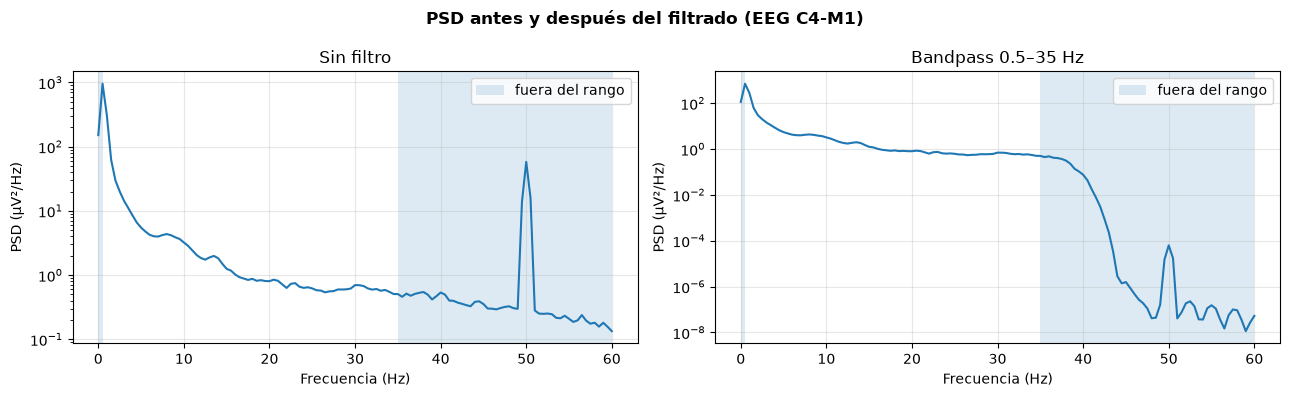

In [43]:
def apply_filters(raw, params):
    """
    Aplica el filtro pasa-banda continuo antes del resampling.
    
    """
    l_freq = params["bandpass_low"]
    h_freq = params["bandpass_high"]

    raw.filter(
        l_freq=l_freq,
        h_freq=h_freq,
        method="fir",
        fir_window="hamming",
        picks="all",
        phase="zero",
        verbose=False,
    )

    print(f"  Bandpass aplicado: {l_freq}–{h_freq} Hz")
    return raw


# Verificación visual con el sujeto de ejemplo
raw_before_filter = raw.copy()
raw = apply_filters(raw, PARAMS)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle(
    "PSD antes y después del filtrado (EEG C4-M1)",
    fontweight="bold",
)

from scipy.signal import welch

for ax, raw_plot, title in zip(
    axes,
    [raw_before_filter, raw],
    ["Sin filtro", "Bandpass 0.5–35 Hz"],
):
    ch_idx = raw_plot.ch_names.index("EEG C4-M1")
    data_ch_uv = raw_plot.get_data()[ch_idx] * 1e6
    f, pxx = welch(
        data_ch_uv,
        fs=raw_plot.info["sfreq"],
        nperseg=512,
    )

    mask = f <= 60
    ax.semilogy(f[mask], pxx[mask], lw=1.5)
    ax.axvspan(0, 0.5, alpha=0.15, label="fuera del rango")
    ax.axvspan(35, 60, alpha=0.15)
    ax.set_xlabel("Frecuencia (Hz)")
    ax.set_ylabel("PSD (µV²/Hz)")
    ax.set_title(title)
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
del raw_before_filter


### Verificación del filtrado mediante PSD

La comparación de PSD permite verificar que el filtro atenúa las componentes por debajo de `0.5 Hz` y por encima de `35 Hz` antes del resampling.

La presencia de energía alrededor de `50 Hz` en la señal original puede ser compatible con interferencia de red, pero no requiere un notch adicional en esta configuración porque el low-pass a `35 Hz` ya la excluye del rango conservado.


---
## 5. Resampling

Después del filtrado continuo, la señal se reduce desde la frecuencia original (`256 Hz` en estos registros) hasta `100 Hz`.

El objetivo no es afirmar que no existe información por encima de `50 Hz`, sino **preservar el rango seleccionado para el análisis principal (`0.5–35 Hz`)** reduciendo al mismo tiempo memoria y costo computacional.

A `100 Hz`, la frecuencia de Nyquist es `50 Hz`, suficiente para representar el rango filtrado de interés.

Para un epoch de 30 s:

```text
256 Hz → 7680 muestras por canal
100 Hz → 3000 muestras por canal
```

La longitud se reduce aproximadamente `2.56×`. Más adelante puede evaluarse `100 Hz` frente a una frecuencia superior como ablación metodológica, especialmente para deep learning.


In [44]:
def apply_resampling(raw, params):
    """Reduce la frecuencia de muestreo a la frecuencia objetivo."""
    original_sfreq = float(raw.info["sfreq"])
    target_sfreq = float(params["target_sfreq"])

    if np.isclose(original_sfreq, target_sfreq):
        print(f"  Ya está en {target_sfreq:g} Hz — sin cambios.")
        return raw

    raw.resample(target_sfreq, verbose=False)

    samples_per_epoch = int(round(
        params["epoch_duration"] * target_sfreq
    ))

    print(f"  Resampling: {original_sfreq:g} Hz → {target_sfreq:g} Hz")
    print(f"  Muestras por epoch: {samples_per_epoch}")
    return raw


In [45]:
raw = apply_resampling(raw, PARAMS)

print(
    f"  Shape datos: ({len(raw.ch_names)}, {raw.n_times}) "
    f"(canales × muestras)"
)
print(f"  Frecuencia final: {raw.info['sfreq']:g} Hz")


  Resampling: 256 Hz → 100 Hz
  Muestras por epoch: 3000
  Shape datos: (7, 2565000) (canales × muestras)
  Frecuencia final: 100 Hz


---
## 6. Estadísticas de normalización — sin normalización permanente

La NB2 **no guarda únicamente una señal z-score**. El dataset final conserva la señal filtrada y resampleada en una escala interpretable (`µV`).

En paralelo se calculan y guardan, por sujeto y canal:

```text
media del canal
std del canal
```

Estas estadísticas permiten aplicar posteriormente:

```text
X_norm = (X - mean) / std
```

cuando corresponda.
Este diseño evita destruir información de amplitud absoluta que puede ser útil para features clásicos como RMS, varianza, rango de amplitud o potencia absoluta.

Las estadísticas se estiman preferentemente con epochs `ok`. Si excepcionalmente no hubiera ninguno, se utilizan `ok + review` como fallback. Los epochs `discard` nunca participan de la referencia.


In [46]:
def compute_channel_stats(X_uv, stats_mask=None, channel_names=None):
    """
    Calcula media y desviación estándar por canal sin transformar X.

    Parameters
    ----------
    X_uv : np.ndarray
        Señal en µV con shape (n_epochs, n_channels, n_samples).
    stats_mask : np.ndarray | None
        Epochs utilizados para estimar las estadísticas.
    channel_names : list[str] | None
        Nombres de canales para el reporte.

    Returns
    -------
    channel_mean_uv : np.ndarray
    channel_std_uv : np.ndarray
    df_stats : pd.DataFrame
    """
    if X_uv.ndim != 3:
        raise ValueError("X_uv debe tener shape (epochs, canales, muestras)")

    n_epochs, n_channels, _ = X_uv.shape

    if stats_mask is None:
        stats_mask = np.ones(n_epochs, dtype=bool)

    stats_mask = np.asarray(stats_mask, dtype=bool)

    if len(stats_mask) != n_epochs:
        raise ValueError("stats_mask debe tener un elemento por epoch")

    if stats_mask.sum() == 0:
        raise ValueError("No hay epochs de referencia para calcular estadísticas")

    means = np.zeros(n_channels, dtype=np.float32)
    stds = np.zeros(n_channels, dtype=np.float32)
    rows = []

    for ch_idx in range(n_channels):
        reference = X_uv[stats_mask, ch_idx, :].ravel()
        mean_ch = float(reference.mean())
        std_ch = float(reference.std())

        if std_ch < 1e-12:
            raise ValueError(
                f"El canal {ch_idx} tiene desviación estándar prácticamente nula"
            )

        means[ch_idx] = mean_ch
        stds[ch_idx] = std_ch

        rows.append({
            "channel_index": ch_idx,
            "channel_name": (
                channel_names[ch_idx]
                if channel_names is not None
                else str(ch_idx)
            ),
            "mean_uv": mean_ch,
            "std_uv": std_ch,
        })

    return means, stds, pd.DataFrame(rows)


### Por qué guardar las estadísticas aunque NB2 no normalice

La normalización por recording puede seguir siendo útil para deep learning y para reducir variabilidad inter-sujeto. Sin embargo, aplicarla de forma irreversible dentro de NB2 obligaría a todas las etapas posteriores a trabajar en unidades adimensionales.

La salida de esta notebook mantiene entonces dos cosas separadas:

```text
X                 → señal procesada en µV
channel_mean_uv   → media por canal
channel_std_uv    → desviación estándar por canal
```

NB3 puede extraer features sobre `X` en escala interpretable y las futuras notebooks de DL pueden normalizar `X` cuando corresponda.


---
## 7. Pipeline completo — procesamiento por sujeto

El pipeline final realiza, para cada sujeto incluido:

1. Carga del EDF y selección de canales.
2. Carga de labels.
3. Extracción de epochs crudos usando el onset real de cada anotación.
4. QC `ok/review/discard` sobre esos epochs alineados.
5. Filtrado continuo `0.5–35 Hz`.
6. Resampling a `100 Hz`.
7. Extracción de los epochs procesados usando exactamente los mismos onsets.
8. Cálculo de media/std por canal sin modificar permanentemente la señal.
9. Eliminación únicamente de epochs `discard`.
10. Guardado de señal, labels, QC, onsets, índices de origen y metadata.

`SN032` y `SN033` se interceptan antes de generar su archivo final y quedan registrados como `excluded_subject_qc`.


In [47]:
import gc

# ============================================================
# Carpetas para guardar resultados
# ============================================================
QC_OUTPUT_PATH = os.path.join(OUTPUT_PATH, "quality_reports")
NORM_OUTPUT_PATH = os.path.join(OUTPUT_PATH, "normalization_stats")

os.makedirs(QC_OUTPUT_PATH, exist_ok=True)
os.makedirs(NORM_OUTPUT_PATH, exist_ok=True)


def empty_subject_result(subject_id, status, reason=""):
    """Estructura para sujetos no procesados."""
    result = {
        "subject": subject_id,
        "status": status,
        "exclusion_reason": reason,
        "n_labels": 0,
        "n_aligned": 0,
        "n_epochs_original": 0,
        "n_epochs_saved": 0,
        "n_ok": 0,
        "n_suspicious_nb1": 0,
        "n_review": 0,
        "n_discard": 0,
        "pct_suspicious_nb1": np.nan,
        "pct_review": np.nan,
        "pct_discard": np.nan,
        "W": 0,
        "N1": 0,
        "N2": 0,
        "N3": 0,
        "REM": 0,
        "original_sfreq": np.nan,
        "processed_sfreq": np.nan,
    }
    return result


# ============================================================
# Pipeline completo para un sujeto
# ============================================================
def process_subject(
    subject_id,
    data_path,
    labels_path,
    output_path,
    params,
    stage_map,
    excluded_subjects=None,
):
    """Procesa un sujeto completo y genera un .npz trazable."""
    excluded_subjects = excluded_subjects or {}

    # Exclusión a priori, antes de generar el dataset final
    if subject_id in excluded_subjects:
        info = excluded_subjects[subject_id]
        result = empty_subject_result(
            subject_id,
            status="excluded_subject_qc",
            reason=info["reason"],
        )
        result["pct_suspicious_nb1"] = info.get(
            "pct_suspicious_nb1",
            np.nan,
        )
        return result

    edf_path = os.path.join(data_path, f"{subject_id}.edf")
    txt_path = os.path.join(labels_path, f"{subject_id}_sleepscoring.txt")
    out_path = os.path.join(output_path, f"{subject_id}.npz")
    qc_csv_path = os.path.join(QC_OUTPUT_PATH, f"{subject_id}_quality.csv")
    norm_csv_path = os.path.join(
        NORM_OUTPUT_PATH,
        f"{subject_id}_normalization_stats.csv",
    )

    if not os.path.exists(txt_path):
        return empty_subject_result(subject_id, "sin_labels")

    raw = None

    try:
        # 1) Señal cruda + canales
        raw = load_and_select_channels(edf_path, params)
        original_sfreq = float(raw.info["sfreq"])
        channel_names = list(raw.ch_names)
        channel_types = list(raw.get_channel_types())

        # 2) Labels
        labels_df = load_labels(txt_path, stage_map)
        n_labels = len(labels_df)

        # 3) Epochs CRUDOS alineados por onset real
        X_qc, y_qc, source_idx_qc, onsets_qc = align_epochs_and_labels(
            data_raw=raw.get_data(),
            labels_df=labels_df,
            sfreq=original_sfreq,
            epoch_duration=params["epoch_duration"],
        )

        eeg_indices = [
            channel_names.index(ch)
            for ch in params["eeg_channels"]
        ]

        # 4) QC sobre señal cruda alineada
        discard_mask, review_mask, df_quality = evaluate_epoch_quality(
            data_epochs=X_qc,
            sfreq=original_sfreq,
            params=params,
            eeg_ch_indices=eeg_indices,
            channel_names=channel_names,
        )

        df_quality.insert(0, "subject", subject_id)
        df_quality.insert(1, "source_epoch_index", source_idx_qc)
        df_quality.insert(2, "recording_onset_s", onsets_qc)
        df_quality["label"] = y_qc
        df_quality["stage"] = [STAGE_SHORT_MAP[int(v)] for v in y_qc]
        df_quality["kept_in_dataset"] = ~discard_mask

        # 5) Filtrado continuo ANTES del resampling
        raw = apply_filters(raw, params)

        # 6) Resampling
        raw = apply_resampling(raw, params)
        processed_sfreq = float(raw.info["sfreq"])

        # 7) Epochs procesados usando los mismos onsets
        X, y, source_idx, onsets = align_epochs_and_labels(
            data_raw=raw.get_data(),
            labels_df=labels_df,
            sfreq=processed_sfreq,
            epoch_duration=params["epoch_duration"],
        )

        # Consistencia crudo ↔ procesado
        if not np.array_equal(source_idx, source_idx_qc):
            raise ValueError(
                "Los índices de epochs alineados difieren entre señal cruda y procesada"
            )

        if not np.array_equal(y, y_qc):
            raise ValueError("Los labels crudos y procesados no coinciden")

        if not np.allclose(onsets, onsets_qc, rtol=0, atol=1e-9):
            raise ValueError("Los onsets crudos y procesados no coinciden")

        # Convertir una sola vez a µV para conservar escala interpretable
        X_uv = (X * 1e6).astype(np.float32)

        # 8) Estadísticas para normalización posterior, sin transformar X
        stats_mask = ~discard_mask & ~review_mask
        normalization_reference = "ok_only"

        if stats_mask.sum() == 0:
            stats_mask = ~discard_mask
            normalization_reference = "ok_and_review_fallback"

        if stats_mask.sum() == 0:
            df_quality.to_csv(qc_csv_path, index=False)
            result = empty_subject_result(
                subject_id,
                status="sin_epochs_utilizables",
            )
            result["n_labels"] = n_labels
            result["n_aligned"] = len(y)
            result["n_epochs_original"] = len(y)
            result["n_discard"] = int(discard_mask.sum())
            result["n_suspicious_nb1"] = int((discard_mask | review_mask).sum())
            result["pct_suspicious_nb1"] = round(
                result["n_suspicious_nb1"] / len(y) * 100, 2
            ) if len(y) else np.nan
            result["pct_discard"] = 100.0
            result["original_sfreq"] = original_sfreq
            result["processed_sfreq"] = processed_sfreq
            return result

        channel_mean_uv, channel_std_uv, df_norm_stats = compute_channel_stats(
            X_uv,
            stats_mask=stats_mask,
            channel_names=channel_names,
        )
        df_norm_stats["normalization_reference"] = normalization_reference

        # 9) Eliminar únicamente discard
        keep_mask = ~discard_mask
        X_final = X_uv[keep_mask]
        y_final = y[keep_mask]
        source_idx_final = source_idx[keep_mask]
        onsets_final = onsets[keep_mask]
        review_mask_final = review_mask[keep_mask]

        qc_status_final = df_quality.loc[
            keep_mask, "status"
        ].astype(str).to_numpy()
        qc_reason_final = df_quality.loc[
            keep_mask, "qc_reason"
        ].fillna("").astype(str).to_numpy()

        # 10) Guardado trazable
        np.savez_compressed(
            out_path,
            X=X_final.astype(np.float32),
            y=y_final.astype(np.int64),
            recording_onset_s=onsets_final.astype(np.float64),
            source_epoch_index=source_idx_final.astype(np.int64),
            qc_status=qc_status_final,
            qc_reason=qc_reason_final,
            nb1_suspicious_flag=df_quality.loc[
                keep_mask, "nb1_suspicious_flag"
            ].to_numpy(dtype=bool),
            nb1_screening_reason=df_quality.loc[
                keep_mask, "nb1_screening_reason"
            ].fillna("").astype(str).to_numpy(),
            review_mask=review_mask_final.astype(bool),
            channel_names=np.asarray(channel_names),
            channel_types=np.asarray(channel_types),
            original_sfreq=np.float32(original_sfreq),
            processed_sfreq=np.float32(processed_sfreq),
            sfreq=np.float32(processed_sfreq),  # alias temporal para compatibilidad
            signal_unit=np.asarray("uV"),
            channel_mean_uv=channel_mean_uv.astype(np.float32),
            channel_std_uv=channel_std_uv.astype(np.float32),
            normalization_reference=np.asarray(normalization_reference),
            subject_id=np.asarray(subject_id),
        )

        df_quality.to_csv(qc_csv_path, index=False)
        df_norm_stats.to_csv(norm_csv_path, index=False)

        n_aligned = len(y)
        n_discard = int(discard_mask.sum())
        n_review = int(review_mask.sum())
        n_suspicious_nb1 = int((discard_mask | review_mask).sum())
        n_ok = int((~discard_mask & ~review_mask).sum())

        result = {
            "subject": subject_id,
            "status": "ok",
            "exclusion_reason": "",
            "n_labels": n_labels,
            "n_aligned": n_aligned,
            "n_epochs_original": n_aligned,
            "n_epochs_saved": len(y_final),
            "n_ok": n_ok,
            "n_suspicious_nb1": n_suspicious_nb1,
            "n_review": n_review,
            "n_discard": n_discard,
            "pct_suspicious_nb1": round(
                n_suspicious_nb1 / n_aligned * 100, 2
            ),
            "pct_review": round(n_review / n_aligned * 100, 2),
            "pct_discard": round(n_discard / n_aligned * 100, 2),
            "original_sfreq": original_sfreq,
            "processed_sfreq": processed_sfreq,
            "normalization_reference": normalization_reference,
            "shape_X": X_final.shape,
        }

        for label_int, stage_name in STAGE_SHORT_MAP.items():
            result[stage_name] = int((y_final == label_int).sum())

        return result

    except Exception as error:
        result = empty_subject_result(
            subject_id,
            status=f"error: {error}",
        )
        return result

    finally:
        if raw is not None:
            del raw
        gc.collect()


### 7.1 — Prueba con un sujeto

Antes de ejecutar los 151 identificadores disponibles, se valida el pipeline completo con `SN001`.


In [48]:
# ============================================================
# Prueba del pipeline con un único sujeto
# ============================================================
TEST_SUBJECT = "SN001"

test_metadata = process_subject(
    subject_id=TEST_SUBJECT,
    data_path=DATA_PATH,
    labels_path=DATA_PATH,
    output_path=OUTPUT_PATH,
    params=PARAMS,
    stage_map=STAGE_MAP,
    excluded_subjects=EXCLUDED_SUBJECTS,
)

print("Resumen del procesamiento:")
for key, value in test_metadata.items():
    print(f"  {key}: {value}")


  Bandpass aplicado: 0.5–35.0 Hz
  Resampling: 256 Hz → 100 Hz
  Muestras por epoch: 3000
Resumen del procesamiento:
  subject: SN001
  status: ok
  exclusion_reason: 
  n_labels: 854
  n_aligned: 854
  n_epochs_original: 854
  n_epochs_saved: 854
  n_ok: 801
  n_suspicious_nb1: 53
  n_review: 53
  n_discard: 0
  pct_suspicious_nb1: 6.21
  pct_review: 6.21
  pct_discard: 0.0
  original_sfreq: 256.0
  processed_sfreq: 100.0
  normalization_reference: ok_only
  shape_X: (854, 7, 3000)
  W: 151
  N1: 109
  N2: 430
  N3: 23
  REM: 141


In [49]:
# ============================================================
# Verificar el archivo generado
# ============================================================
test_npz_path = os.path.join(OUTPUT_PATH, f"{TEST_SUBJECT}.npz")
test_data = np.load(test_npz_path, allow_pickle=True)

print("Variables guardadas:")
print(test_data.files)

print("\nShapes:")
for key in [
    "X",
    "y",
    "recording_onset_s",
    "source_epoch_index",
    "qc_status",
    "qc_reason",
    "nb1_suspicious_flag",
    "nb1_screening_reason",
    "review_mask",
]:
    print(f"{key:22s}: {test_data[key].shape}")

print("\nMetadata:")
print(f"Sujeto:             {test_data['subject_id']}")
print(f"Canales:            {test_data['channel_names']}")
print(f"Tipos:              {test_data['channel_types']}")
print(f"Frecuencia original:{float(test_data['original_sfreq']):g} Hz")
print(f"Frecuencia final:   {float(test_data['processed_sfreq']):g} Hz")
print(f"Unidad de X:        {test_data['signal_unit']}")
print(f"Media por canal:    {test_data['channel_mean_uv']}")
print(f"Std por canal:      {test_data['channel_std_uv']}")

n = len(test_data["y"])
consistent = all(
    len(test_data[key]) == n
    for key in [
        "X",
        "recording_onset_s",
        "source_epoch_index",
        "qc_status",
        "qc_reason",
        "review_mask",
    ]
)
print(f"\nConsistencia de longitudes: {consistent}")
print(f"Epochs review conservados:  {int(test_data['review_mask'].sum())}")


Variables guardadas:
['X', 'y', 'recording_onset_s', 'source_epoch_index', 'qc_status', 'qc_reason', 'nb1_suspicious_flag', 'nb1_screening_reason', 'review_mask', 'channel_names', 'channel_types', 'original_sfreq', 'processed_sfreq', 'sfreq', 'signal_unit', 'channel_mean_uv', 'channel_std_uv', 'normalization_reference', 'subject_id']

Shapes:
X                     : (854, 7, 3000)
y                     : (854,)
recording_onset_s     : (854,)
source_epoch_index    : (854,)
qc_status             : (854,)
qc_reason             : (854,)
nb1_suspicious_flag   : (854,)
nb1_screening_reason  : (854,)
review_mask           : (854,)

Metadata:
Sujeto:             SN001
Canales:            ['EEG F4-M1' 'EEG C4-M1' 'EEG O2-M1' 'EEG C3-M2' 'EOG E1-M2' 'EOG E2-M2'
 'EMG chin']
Tipos:              ['eeg' 'eeg' 'eeg' 'eeg' 'eog' 'eog' 'emg']
Frecuencia original:256 Hz
Frecuencia final:   100 Hz
Unidad de X:        uV
Media por canal:    [ 0.00300659 -0.00220207  0.00010959 -0.00301881  0.0022138  -0.

### 7.2 — Ejecución global

La ejecución recorre todos los EDF disponibles, pero `SN032` y `SN033` se registran como `excluded_subject_qc` y **no generan dataset final**. Por lo tanto, el conjunto utilizable pasa de 151 a 149 sujetos antes de cualquier split de train/validation/test.


In [50]:
# ============================================================
# Carpetas y configuración reproducible
# ============================================================
OUTPUT_PATH = "../data/processed"
QC_OUTPUT_PATH = os.path.join(OUTPUT_PATH, "quality_reports")
NORM_OUTPUT_PATH = os.path.join(OUTPUT_PATH, "normalization_stats")

os.makedirs(OUTPUT_PATH, exist_ok=True)
os.makedirs(QC_OUTPUT_PATH, exist_ok=True)
os.makedirs(NORM_OUTPUT_PATH, exist_ok=True)

# Evitar que artefactos de ejecuciones anteriores hagan parecer
# que un sujeto excluido sigue formando parte del dataset final.
for subject_id in EXCLUDED_SUBJECTS:
    stale_paths = [
        os.path.join(OUTPUT_PATH, f"{subject_id}.npz"),
        os.path.join(QC_OUTPUT_PATH, f"{subject_id}_quality.csv"),
        os.path.join(NORM_OUTPUT_PATH, f"{subject_id}_normalization_stats.csv"),
        os.path.join(NORM_OUTPUT_PATH, f"{subject_id}_normalization.csv"),
    ]
    for stale_path in stale_paths:
        if os.path.exists(stale_path):
            os.remove(stale_path)

preprocessing_config = {
    "pipeline_version": "nb2_v4_scientific_qc",
    "epoch_duration_s": EPOCH_DURATION_S,
    "channels": {
        "eeg": PARAMS["eeg_channels"],
        "eog": PARAMS["eog_channels"],
        "emg": PARAMS["emg_channels"],
    },
    "stage_map": STAGE_MAP,
    "filter": {
        "low_hz": PARAMS["bandpass_low"],
        "high_hz": PARAMS["bandpass_high"],
        "notch_hz": None,
    },
    "target_sfreq_hz": PARAMS["target_sfreq"],
    "qc": {
        "nb1_screening": {
            "channels": "EEG_only",
            "amplitude_threshold_uv": AMPLITUDE_THRESHOLD_UV,
            "comparison": ">",
            "flat_duration_s": FLAT_DURATION_S,
            "flat_comparison": ">=",
        },
        "nb2_discard_policy": {
            "criterion": "severe_multichannel_flatline",
            "severe_flat_fraction_discard": (
                PARAMS["severe_flat_fraction_discard"]
            ),
            "comparison": ">",
            "require_all_eeg_channels_flat_for_discard": (
                PARAMS["require_all_eeg_channels_flat_for_discard"]
            ),
            "amplitude_only_can_discard": False,
            "rationale": (
                "Literature-backed >50% flatline threshold; conservative "
                "project-specific adaptation requires all selected EEG channels."
            ),
            "references": [
                "Vallat & Walker, eLife 2021, DOI:10.7554/eLife.70092",
                "Sommerauer et al., npj Digital Medicine 2026, "
                "DOI:10.1038/s41746-026-02946-2",
            ],
        },
        "invariant": "suspicious_NB1 == review_NB2 OR discard_NB2",
    },
    "excluded_subjects": EXCLUDED_SUBJECTS,
    "saved_signal_unit": "uV",
    "permanent_normalization": False,
    "processing_order": [
        "load_and_select_channels",
        "load_labels",
        "align_raw_epochs_by_recording_onset",
        "epoch_qc_on_raw_signal",
        "continuous_bandpass_filter",
        "resample",
        "align_processed_epochs_by_recording_onset",
        "compute_channel_normalization_stats",
        "remove_discard_only",
        "save",
    ],
}

config_path = os.path.join(OUTPUT_PATH, "preprocessing_config.json")
with open(config_path, "w", encoding="utf-8") as f:
    json.dump(preprocessing_config, f, indent=2, ensure_ascii=False)

print("Carpetas de salida:")
print(f"  Datos procesados:      {OUTPUT_PATH}")
print(f"  Reportes de calidad:   {QC_OUTPUT_PATH}")
print(f"  Stats normalización:   {NORM_OUTPUT_PATH}")
print(f"  Configuración:         {config_path}")


Carpetas de salida:
  Datos procesados:      ../data/processed
  Reportes de calidad:   ../data/processed\quality_reports
  Stats normalización:   ../data/processed\normalization_stats
  Configuración:         ../data/processed\preprocessing_config.json


In [51]:
# ============================================================
# Procesar todos los sujetos disponibles
# ============================================================
LABELS_PATH = DATA_PATH

# Si es True, reprocesa todos los sujetos aunque ya existan resultados
FORCE_REPROCESS = False

edf_files = sorted([
    file_name[:-4]
    for file_name in os.listdir(DATA_PATH)
    if (
        file_name.lower().endswith(".edf")
        and "sleepscoring" not in file_name.lower()
    )
])

print(f"Sujetos detectados: {len(edf_files)}")
print(f"Exclusiones a priori: {len(EXCLUDED_SUBJECTS)}")
print(
    "Sujetos esperados en dataset final: "
    f"{len([s for s in edf_files if s not in EXCLUDED_SUBJECTS])}\n"
)

# Cargar resumen anterior, si existe
summary_path = os.path.join(OUTPUT_PATH, "processing_summary.csv")

if os.path.exists(summary_path):
    previous_summary = pd.read_csv(summary_path)
else:
    previous_summary = pd.DataFrame()

results = []

for subject_id in edf_files:
    print(f"  → {subject_id}", end=" ")

    # --------------------------------------------------------
    # Verificar si el sujeto ya fue procesado completamente
    # --------------------------------------------------------
    npz_path = os.path.join(
        OUTPUT_PATH,
        f"{subject_id}.npz"
    )

    qc_path = os.path.join(
        QC_OUTPUT_PATH,
        f"{subject_id}_quality.csv"
    )

    norm_path = os.path.join(
        NORM_OUTPUT_PATH,
        f"{subject_id}_normalization_stats.csv"
    )

    outputs_exist = (
        os.path.exists(npz_path)
        and os.path.exists(qc_path)
        and os.path.exists(norm_path)
    )

    # Buscar metadata previa del sujeto
    has_previous_metadata = (
        not previous_summary.empty
        and "subject" in previous_summary.columns
        and subject_id in previous_summary["subject"].values
    )

    # Si ya está completamente procesado, reutilizar el resultado
    if (
        not FORCE_REPROCESS
        and subject_id not in EXCLUDED_SUBJECTS
        and outputs_exist
        and has_previous_metadata
    ):
        metadata = (
            previous_summary.loc[
                previous_summary["subject"] == subject_id
            ]
            .iloc[0]
            .to_dict()
        )

        results.append(metadata)

        print(
            "[already_processed] "
            f"— guardados: {int(metadata['n_epochs_saved'])}"
        )
        continue

    # --------------------------------------------------------
    # Procesar sujeto
    # --------------------------------------------------------
    metadata = process_subject(
        subject_id=subject_id,
        data_path=DATA_PATH,
        labels_path=LABELS_PATH,
        output_path=OUTPUT_PATH,
        params=PARAMS,
        stage_map=STAGE_MAP,
        excluded_subjects=EXCLUDED_SUBJECTS,
    )

    results.append(metadata)

    if metadata["status"] == "excluded_subject_qc":
        print("[excluded_subject_qc]")

    else:
        print(
            f"[{metadata['status']}] "
            f"— guardados: {metadata['n_epochs_saved']} "
            f"| review: {metadata['n_review']} "
            f"| discard: {metadata['n_discard']}"
        )


# ============================================================
# Resumen global
# ============================================================
df_results = pd.DataFrame(results)

df_results.to_csv(
    summary_path,
    index=False
)

print("\nResumen global:")

display(
    df_results[
        [
            "subject",
            "status",
            "exclusion_reason",
            "n_labels",
            "n_aligned",
            "n_epochs_saved",
            "n_ok",
            "n_suspicious_nb1",
            "n_review",
            "n_discard",
            "pct_suspicious_nb1",
            "pct_review",
            "pct_discard",
            "W",
            "N1",
            "N2",
            "N3",
            "REM",
        ]
    ]
)

Sujetos detectados: 151
Exclusiones a priori: 2
Sujetos esperados en dataset final: 149

  → SN001 [already_processed] — guardados: 854
  → SN002 [already_processed] — guardados: 856
  → SN003 [already_processed] — guardados: 954
  → SN004 [already_processed] — guardados: 1016
  → SN005 [already_processed] — guardados: 959
  → SN006 [already_processed] — guardados: 866
  → SN007 [already_processed] — guardados: 1034
  → SN008 [already_processed] — guardados: 847
  → SN009 [already_processed] — guardados: 901
  → SN010 [already_processed] — guardados: 924
  → SN011 [already_processed] — guardados: 1141
  → SN012 [already_processed] — guardados: 937
  → SN013 [already_processed] — guardados: 1004
  → SN015 [already_processed] — guardados: 867
  → SN016 [already_processed] — guardados: 1088
  → SN017 [already_processed] — guardados: 1114
  → SN018 [already_processed] — guardados: 862
  → SN019 [already_processed] — guardados: 840
  → SN020 [already_processed] — guardados: 948
  → SN021 [a

,subject,status,exclusion_reason,n_labels,n_aligned,n_epochs_saved,n_ok,n_suspicious_nb1,n_review,n_discard,pct_suspicious_nb1,pct_review,pct_discard,W,N1,N2,N3,REM
0,SN001,ok,NaN,854,854,854,801,53,53,0,6.21,6.21,0.0,151,109,430,23,141
1,SN002,ok,NaN,856,856,856,821,35,35,0,4.09,4.09,0.0,82,67,309,224,174
2,SN003,ok,NaN,954,954,954,877,77,77,0,8.07,8.07,0.0,403,81,168,150,152
3,SN004,ok,NaN,1016,1016,1016,1003,13,13,0,1.28,1.28,0.0,80,91,534,64,247
4,SN005,ok,NaN,959,959,959,849,110,110,0,11.47,11.47,0.0,201,141,341,149,127
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
146,SN150,ok,NaN,589,589,589,559,30,30,0,5.09,5.09,0.0,9,15,292,195,78
147,SN151,ok,NaN,844,844,844,819,25,25,0,2.96,2.96,0.0,189,66,335,148,106
148,SN152,ok,NaN,999,999,999,832,167,167,0,16.72,16.72,0.0,110,76,322,277,214
149,SN153,ok,NaN,902,902,902,877,25,25,0,2.77,2.77,0.0,19,74,443,184,182


---
## 8. Verificación global

Las verificaciones siguientes comprueban cuatro aspectos:

1. que los `.npz` tengan la metadata esperada;
2. que el dataset final contenga únicamente los 149 sujetos no excluidos;
3. que los casos con mucho descarte queden identificados para revisión sin exclusión automática;
4. que el QC no perjudique de forma desproporcionada a una etapa del sueño, especialmente `N1`.


In [52]:
# ============================================================
# Verificación de un archivo procesado
# ============================================================
sample_processed_path = os.path.join(OUTPUT_PATH, "SN001.npz")
sample_data = np.load(sample_processed_path, allow_pickle=True)

print("Variables guardadas:")
print(sample_data.files)

print("\nShapes:")
for key in [
    "X",
    "y",
    "recording_onset_s",
    "source_epoch_index",
    "qc_status",
    "qc_reason",
    "nb1_suspicious_flag",
    "nb1_screening_reason",
    "review_mask",
]:
    print(f"{key:22s}: {sample_data[key].shape}")

print("\nMetadata:")
print(f"Canales:          {sample_data['channel_names']}")
print(f"Tipos:            {sample_data['channel_types']}")
print(f"Frecuencia final: {float(sample_data['processed_sfreq']):g} Hz")
print(f"Unidad de X:      {sample_data['signal_unit']}")

print("\nResumen:")
print(f"Epochs guardados: {len(sample_data['y'])}")
print(f"Epochs review:    {int(sample_data['review_mask'].sum())}")
print(f"Onset inicial:    {sample_data['recording_onset_s'][0]:.2f} s")


Variables guardadas:
['X', 'y', 'recording_onset_s', 'source_epoch_index', 'qc_status', 'qc_reason', 'nb1_suspicious_flag', 'nb1_screening_reason', 'review_mask', 'channel_names', 'channel_types', 'original_sfreq', 'processed_sfreq', 'sfreq', 'signal_unit', 'channel_mean_uv', 'channel_std_uv', 'normalization_reference', 'subject_id']

Shapes:
X                     : (854, 7, 3000)
y                     : (854,)
recording_onset_s     : (854,)
source_epoch_index    : (854,)
qc_status             : (854,)
qc_reason             : (854,)
nb1_suspicious_flag   : (854,)
nb1_screening_reason  : (854,)
review_mask           : (854,)

Metadata:
Canales:          ['EEG F4-M1' 'EEG C4-M1' 'EEG O2-M1' 'EEG C3-M2' 'EOG E1-M2' 'EOG E2-M2'
 'EMG chin']
Tipos:            ['eeg' 'eeg' 'eeg' 'eeg' 'eog' 'eog' 'emg']
Frecuencia final: 100 Hz
Unidad de X:      uV

Resumen:
Epochs guardados: 854
Epochs review:    53
Onset inicial:    0.00 s


In [53]:
# ============================================================
# Resumen global del procesamiento
# ============================================================
processed_mask = df_results["status"].eq("ok")
excluded_mask = df_results["status"].eq("excluded_subject_qc")

print(f"Sujetos detectados:           {len(df_results)}")
print(f"Sujetos procesados:           {int(processed_mask.sum())}")
print(f"Sujetos excluidos por QC NB1: {int(excluded_mask.sum())}")
print(f"Epochs alineados (149):       {int(df_results.loc[processed_mask, 'n_aligned'].sum())}")
print(f"Epochs guardados:             {int(df_results.loc[processed_mask, 'n_epochs_saved'].sum())}")
print(f"Epochs sospechosos NB1:       {int(df_results.loc[processed_mask, 'n_suspicious_nb1'].sum())}")
print(f"Epochs review:                {int(df_results.loc[processed_mask, 'n_review'].sum())}")
print(f"Epochs descartados:           {int(df_results.loc[processed_mask, 'n_discard'].sum())}")

print("\nDistribución final de clases después de exclusiones y QC:")
final_class_counts = (
    df_results.loc[processed_mask, STAGE_ORDER]
    .sum()
    .astype(int)
    .rename("n_epochs")
    .to_frame()
)
final_class_counts["pct"] = (
    final_class_counts["n_epochs"]
    / final_class_counts["n_epochs"].sum()
    * 100
)
display(final_class_counts.round(2))


Sujetos detectados:           151
Sujetos procesados:           149
Sujetos excluidos por QC NB1: 2
Epochs alineados (149):       135533
Epochs guardados:             135471
Epochs sospechosos NB1:       10053
Epochs review:                9991
Epochs descartados:           62

Distribución final de clases después de exclusiones y QC:


,n_epochs,pct
W,23493,17.34
N1,14846,10.96
N2,49455,36.51
N3,26671,19.69
REM,21006,15.51


### 8.1 — Sujetos con alta proporción de epochs sospechosos

La NB1 utiliza `70%` de epochs sospechosos como umbral para **seleccionar casos extremos para revisión**, no como regla automática de exclusión.

En NB2 se conserva esa interpretación:

- `SN032` y `SN033` ya están excluidos a priori por la revisión detallada de NB1;
- `SN020` se conserva;
- para los demás sujetos, `pct_suspicious_nb1` y `pct_discard` funcionan únicamente como señales de inspección.

No se excluye automáticamente ningún sujeto adicional por superar un porcentaje.


In [54]:
display(
    df_results.loc[
        df_results["status"].eq("ok"),
        [
            "subject",
            "n_aligned",
            "n_ok",
            "n_suspicious_nb1",
            "n_review",
            "n_discard",
            "pct_suspicious_nb1",
            "pct_review",
            "pct_discard",
        ],
    ]
    .sort_values("pct_discard", ascending=False)
    .head(20)
)


,subject,n_aligned,n_ok,n_suspicious_nb1,n_review,n_discard,pct_suspicious_nb1,pct_review,pct_discard
112,SN115,857,700,157,101,56,18.32,11.79,6.53
26,SN028,902,833,69,66,3,7.65,7.32,0.33
87,SN090,907,876,31,28,3,3.42,3.09,0.33
1,SN002,856,821,35,35,0,4.09,4.09,0.00
0,SN001,854,801,53,53,0,6.21,6.21,0.00
5,SN006,866,762,104,104,0,12.01,12.01,0.00
6,SN007,1034,983,51,51,0,4.93,4.93,0.00
7,SN008,847,768,79,79,0,9.33,9.33,0.00
8,SN009,901,855,46,46,0,5.11,5.11,0.00
9,SN010,924,866,58,58,0,6.28,6.28,0.00


In [55]:
# Casos a inspeccionar: criterio exploratorio de NB1, NO exclusión automática
SUBJECT_REVIEW_THRESHOLD_PCT = REVIEW_THRESHOLD_PCT

df_subjects_to_review = df_results[
    df_results["status"].eq("ok")
    & (
        df_results["pct_suspicious_nb1"]
        >= SUBJECT_REVIEW_THRESHOLD_PCT
    )
].sort_values("pct_suspicious_nb1", ascending=False)

print(
    f"Sujetos incluidos con epochs sospechosos NB1 >= "
    f"{SUBJECT_REVIEW_THRESHOLD_PCT:.0f}%: "
    f"{len(df_subjects_to_review)}"
)
display(df_subjects_to_review)


Sujetos incluidos con epochs sospechosos NB1 >= 70%: 0


,subject,status,exclusion_reason,n_labels,n_aligned,n_epochs_original,n_epochs_saved,n_ok,n_suspicious_nb1,n_review,...,original_sfreq,processed_sfreq,normalization_reference,shape_X,W,N1,N2,N3,REM,subject_quality


In [56]:
# ============================================================
# Consolidar reportes de calidad SOLO de sujetos incluidos
# ============================================================
processed_subject_ids = df_results.loc[
    df_results["status"].eq("ok"),
    "subject",
].tolist()

quality_paths = [
    os.path.join(QC_OUTPUT_PATH, f"{subject_id}_quality.csv")
    for subject_id in processed_subject_ids
]
quality_paths = [p for p in quality_paths if os.path.exists(p)]

if not quality_paths:
    raise FileNotFoundError(
        "No se encontraron reportes de calidad de sujetos procesados"
    )

df_quality_all = pd.concat(
    [pd.read_csv(path) for path in quality_paths],
    ignore_index=True,
)

qc_epochs_path = os.path.join(OUTPUT_PATH, "qc_epochs.csv")
df_quality_all.to_csv(qc_epochs_path, index=False)

print(f"Sujetos con reporte QC: {df_quality_all['subject'].nunique()}")
print(f"Epochs analizados:      {len(df_quality_all)}")
print(f"Reporte consolidado:    {qc_epochs_path}")

display(df_quality_all.head())


Sujetos con reporte QC: 149
Epochs analizados:      135533
Reporte consolidado:    ../data/processed\qc_epochs.csv


,subject,source_epoch_index,recording_onset_s,aligned_epoch_index,status,nb1_suspicious_flag,nb1_screening_reason,discard_flag,review_flag,qc_reason,max_abs_uv,max_flat_seconds,max_flat_fraction,n_severe_flat_channels,severe_flat_channels,label,stage,kept_in_dataset
0,SN001,0,0.0,0,ok,False,NaN,False,False,NaN,72.47,0.008,0.0003,0,NaN,0,W,True
1,SN001,1,30.0,1,ok,False,NaN,False,False,NaN,57.24,0.008,0.0003,0,NaN,0,W,True
2,SN001,2,60.0,2,ok,False,NaN,False,False,NaN,59.44,0.012,0.0004,0,NaN,0,W,True
3,SN001,3,90.0,3,ok,False,NaN,False,False,NaN,53.85,0.008,0.0003,0,NaN,0,W,True
4,SN001,4,120.0,4,ok,False,NaN,False,False,NaN,54.29,0.008,0.0003,0,NaN,0,W,True


In [57]:
# ============================================================
# QC por etapa del sueño: screening NB1 + acción NB2
# ============================================================
stage_qc = (
    df_quality_all
    .groupby("stage", observed=False)
    .agg(
        n_original=("status", "size"),
        n_suspicious_nb1=(
            "status",
            lambda s: int((s != "ok").sum())
        ),
        n_ok=("status", lambda s: int((s == "ok").sum())),
        n_review=("status", lambda s: int((s == "review").sum())),
        n_discard=("status", lambda s: int((s == "discard").sum())),
    )
    .reindex(STAGE_ORDER)
)

stage_qc["n_kept"] = stage_qc["n_original"] - stage_qc["n_discard"]
stage_qc["suspicious_pct_nb1"] = (
    stage_qc["n_suspicious_nb1"] / stage_qc["n_original"] * 100
)
stage_qc["review_pct"] = stage_qc["n_review"] / stage_qc["n_original"] * 100
stage_qc["discard_pct"] = stage_qc["n_discard"] / stage_qc["n_original"] * 100
stage_qc["kept_pct"] = stage_qc["n_kept"] / stage_qc["n_original"] * 100

display(stage_qc.round(2))


,n_original,n_suspicious_nb1,n_ok,n_review,n_discard,n_kept,suspicious_pct_nb1,review_pct,discard_pct,kept_pct
stage,,,,,,,,,,
W,23506,5029,18477,5016,13,23493,21.39,21.34,0.06,99.94
N1,14851,2027,12824,2022,5,14846,13.65,13.62,0.03,99.97
N2,49496,1738,47758,1697,41,49455,3.51,3.43,0.08,99.92
N3,26671,594,26077,594,0,26671,2.23,2.23,0.00,100.00
REM,21009,665,20344,662,3,21006,3.17,3.15,0.01,99.99


In [58]:
# ============================================================
# ¿El QC cambia la distribución de clases?
# ============================================================
stage_distribution = stage_qc[["n_original", "n_kept"]].copy()

stage_distribution["original_pct"] = (
    stage_distribution["n_original"]
    / stage_distribution["n_original"].sum()
    * 100
)
stage_distribution["final_pct"] = (
    stage_distribution["n_kept"]
    / stage_distribution["n_kept"].sum()
    * 100
)
stage_distribution["delta_pp"] = (
    stage_distribution["final_pct"]
    - stage_distribution["original_pct"]
)

display(stage_distribution.round(2))


,n_original,n_kept,original_pct,final_pct,delta_pp
stage,,,,,
W,23506,23493,17.34,17.34,-0.00
N1,14851,14846,10.96,10.96,0.00
N2,49496,49455,36.52,36.51,-0.01
N3,26671,26671,19.68,19.69,0.01
REM,21009,21006,15.50,15.51,0.00


### 8.2 — QC a nivel sujeto

`SN032` y `SN033` ya tienen una decisión explícita: `excluded_subject_qc` por evidencia global de mala adquisición observada en NB1 (clipping/saturación extensa y multicanal).

`SN020` se mantiene, tal como concluye NB1.

Para el resto se utiliza una clasificación descriptiva basada principalmente en el porcentaje de epochs sospechosos según el screening de NB1. Esta clasificación sirve para priorizar inspecciones y **no elimina automáticamente ningún sujeto adicional**.


In [59]:
def classify_subject_quality(row):
    """Clasificación descriptiva para revisión; no modifica el dataset."""
    if row["status"] == "excluded_subject_qc":
        return "excluded_subject_qc"

    if row["status"] != "ok":
        return "processing_issue"

    pct_suspicious = row["pct_suspicious_nb1"]

    if pd.isna(pct_suspicious):
        return "unknown"
    if pct_suspicious >= REVIEW_THRESHOLD_PCT:
        return "review_high_suspicious"
    if pct_suspicious >= 40:
        return "review"
    return "ok"


df_results["subject_quality"] = df_results.apply(
    classify_subject_quality,
    axis=1,
)

display(
    df_results[
        [
            "subject",
            "status",
            "n_epochs_saved",
            "n_suspicious_nb1",
            "n_review",
            "n_discard",
            "pct_suspicious_nb1",
            "pct_discard",
            "subject_quality",
        ]
    ]
    .sort_values(
        "pct_suspicious_nb1",
        ascending=False,
        na_position="last",
    )
    .head(20)
)

# Actualizar processing_summary.csv con la clasificación descriptiva final
df_results.to_csv(summary_path, index=False)
print(f"Resumen actualizado: {summary_path}")


,subject,status,n_epochs_saved,n_suspicious_nb1,n_review,n_discard,pct_suspicious_nb1,pct_discard,subject_quality
30,SN032,excluded_subject_qc,0,0,0,0,95.50,NaN,excluded_subject_qc
31,SN033,excluded_subject_qc,0,0,0,0,81.00,NaN,excluded_subject_qc
18,SN020,ok,948,400,400,0,42.19,0.00,review
130,SN133,ok,995,328,328,0,32.96,0.00,ok
47,SN049,ok,801,256,256,0,31.96,0.00,ok
16,SN018,ok,862,234,234,0,27.15,0.00,ok
69,SN072,ok,1058,218,218,0,20.60,0.00,ok
76,SN079,ok,1117,222,222,0,19.87,0.00,ok
112,SN115,ok,801,157,101,56,18.32,6.53,ok
122,SN125,ok,1202,219,219,0,18.22,0.00,ok


Resumen actualizado: ../data/processed\processing_summary.csv


In [60]:
display(
    df_results["subject_quality"]
    .value_counts()
    .rename_axis("subject_quality")
    .reset_index(name="n_subjects")
)

,subject_quality,n_subjects
0,ok,148
1,excluded_subject_qc,2
2,review,1


In [61]:
def plot_subject_quality_timeline(subject_id, output_path):
    """Muestra ok/review/discard a lo largo de la noche."""
    quality_path = os.path.join(
        output_path,
        "quality_reports",
        f"{subject_id}_quality.csv",
    )

    if not os.path.exists(quality_path):
        print(f"Sin reporte QC generado para {subject_id}")
        return

    df_subject = pd.read_csv(quality_path)
    status_map = {"ok": 0, "review": 1, "discard": 2}
    y_values = df_subject["status"].map(status_map)
    time_h = df_subject["recording_onset_s"] / SECONDS_PER_HOUR

    plt.figure(figsize=(14, 3))
    plt.scatter(time_h, y_values, s=12)
    plt.yticks([0, 1, 2], ["ok", "review", "discard"])
    plt.xlabel("Tiempo desde el inicio del recording (h)")
    plt.ylabel("Estado")
    plt.title(f"Calidad de señal a lo largo del recording — {subject_id}")
    plt.grid(alpha=0.3)
    plt.show()


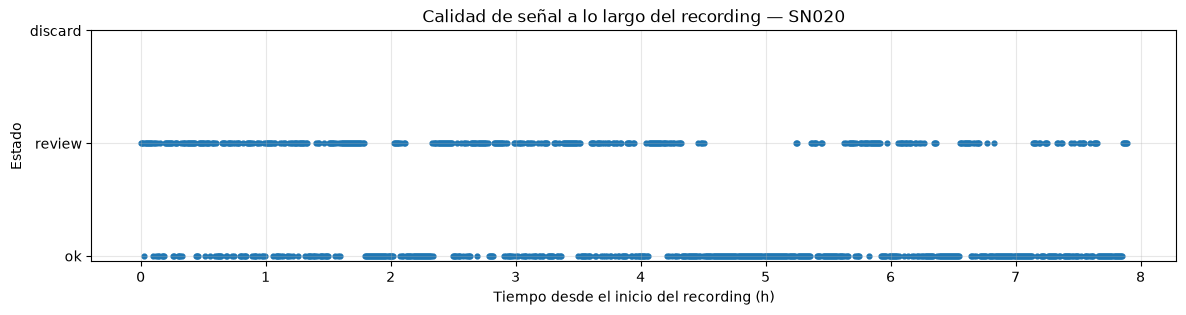

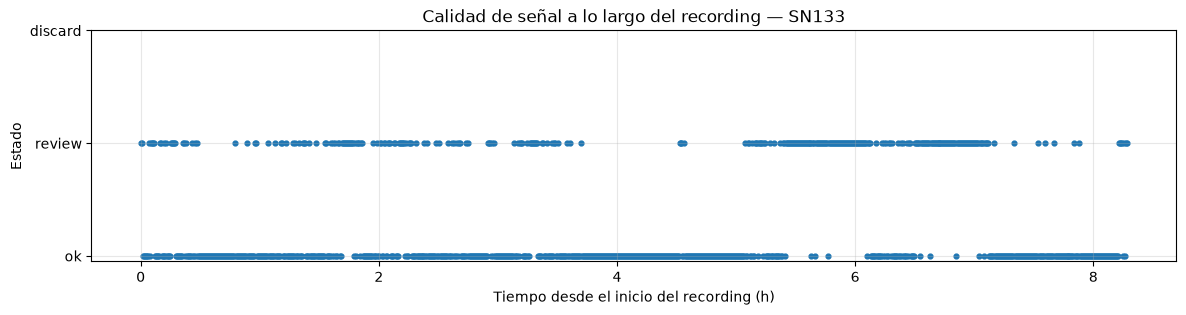

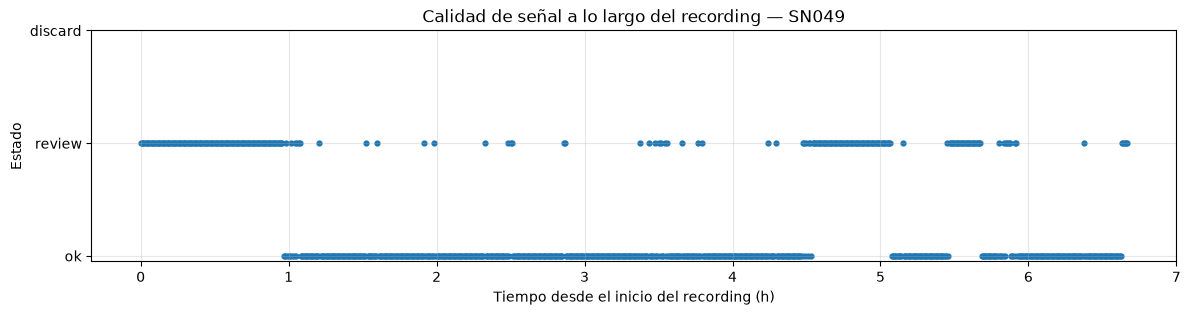

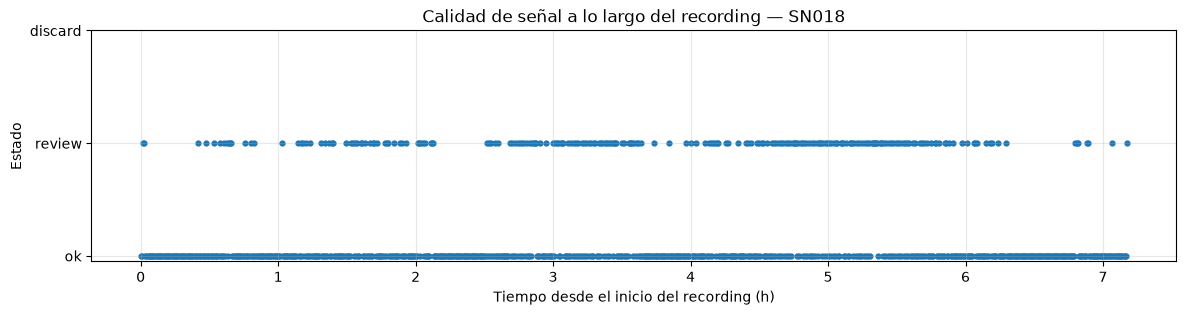

In [62]:
# Mostrar automáticamente los casos incluidos con mayor porcentaje de descarte
subjects_for_timeline = (
    df_results.loc[df_results["status"].eq("ok")]
    .sort_values("pct_suspicious_nb1", ascending=False)
    .head(4)["subject"]
    .tolist()
)

for subject_id in subjects_for_timeline:
    plot_subject_quality_timeline(subject_id, OUTPUT_PATH)


In [63]:
def summarize_subject_reasons(subject_id, output_path):
    quality_path = os.path.join(
        output_path,
        "quality_reports",
        f"{subject_id}_quality.csv",
    )

    if not os.path.exists(quality_path):
        print(f"Sin reporte QC generado para {subject_id}")
        return

    df_subject = pd.read_csv(quality_path)
    print(f"Resumen de calidad — {subject_id}")

    display(
        df_subject["status"]
        .value_counts()
        .rename_axis("status")
        .reset_index(name="n_epochs")
    )

    print("\nMotivos de descarte:")
    display(
        df_subject.loc[
            df_subject["status"].eq("discard"),
            "qc_reason",
        ]
        .value_counts()
        .rename_axis("reason")
        .reset_index(name="n_epochs")
        .head(15)
    )


In [64]:
for subject_id in subjects_for_timeline[:2]:
    summarize_subject_reasons(subject_id, OUTPUT_PATH)


Resumen de calidad — SN020


,status,n_epochs
0,ok,548
1,review,400



Motivos de descarte:


,reason,n_epochs


Resumen de calidad — SN133


,status,n_epochs
0,ok,667
1,review,328



Motivos de descarte:


,reason,n_epochs


## Verificación global del procesamiento

Esta versión recalcula todos los totales y los registra en:

```text
processing_summary.csv
qc_epochs.csv
preprocessing_config.json
```

La relación con NB1 queda explícita:

```text
NB1 sospechoso  =  NB2 review ∪ NB2 discard
NB1 limpio      =  NB2 ok
```

Dentro de NB2:

```text
ok       → se conserva
review   → se conserva y queda identificado
discard  → se elimina únicamente por pérdida severa y generalizada de EEG
```

La política de `discard` ya **no utiliza** `1500 µV`, `5 s`, `1% de muestras` ni un número arbitrario de canales afectados. El único descarte automático por epoch corresponde a un flatline continuo que ocupa **más del 50% del epoch en los cuatro EEG seleccionados**.

El 50% se apoya en un pipeline publicado basado en U-Sleep; exigir los cuatro EEG es una adaptación conservadora específica de este proyecto. Las anomalías de amplitud permanecen como `review`, coherentemente con una estrategia que prioriza conservar PSG clínico real salvo pérdida inequívoca de señal.

Finalmente, la distribución por etapa se analiza tanto para el screening como para el descarte final, con especial atención a `N1`, para comprobar que el preprocessing no altere de forma desproporcionada ninguna clase.


### Sujetos excluidos del dataset final

La exclusión de `SN032` y `SN033` se determina por criterios de calidad de señal observados durante el análisis exploratorio de NB1, **antes del entrenamiento de los modelos**.

```text
SN032 → excluded_subject_qc
SN033 → excluded_subject_qc
```

En NB1 ambos registros mostraron deterioro global de adquisición, con aproximadamente `93.60%` y `79.31%` de epochs descartables, respectivamente. Conservar únicamente una fracción pequeña de esas noches podría producir una representación poco fiable del sujeto.

La ejecución global mantiene los 151 identificadores en `processing_summary.csv` para trazabilidad, pero solo genera `.npz` para los 149 sujetos utilizables. Los splits de train/validation/test deberán realizarse posteriormente **a nivel sujeto sobre esos 149 registros**, nunca por epoch.

Para cualquier otro sujeto con descarte elevado se conserva la política de revisión manual/analítica; no existe una regla automática adicional de exclusión.


## 9. Visualización de epochs procesados por etapa del sueño

Para verificar visualmente la salida final se selecciona un epoch `ok` representativo de cada etapa y se grafican los siete canales.

A diferencia de la versión anterior, `X` ya no contiene z-scores: la señal guardada está filtrada, resampleada a `100 Hz` y expresada en `µV`. Esto permite interpretar amplitudes y utilizar la misma salida posteriormente para features clásicos o para normalización específica de deep learning.


Sujetos procesados disponibles: 149


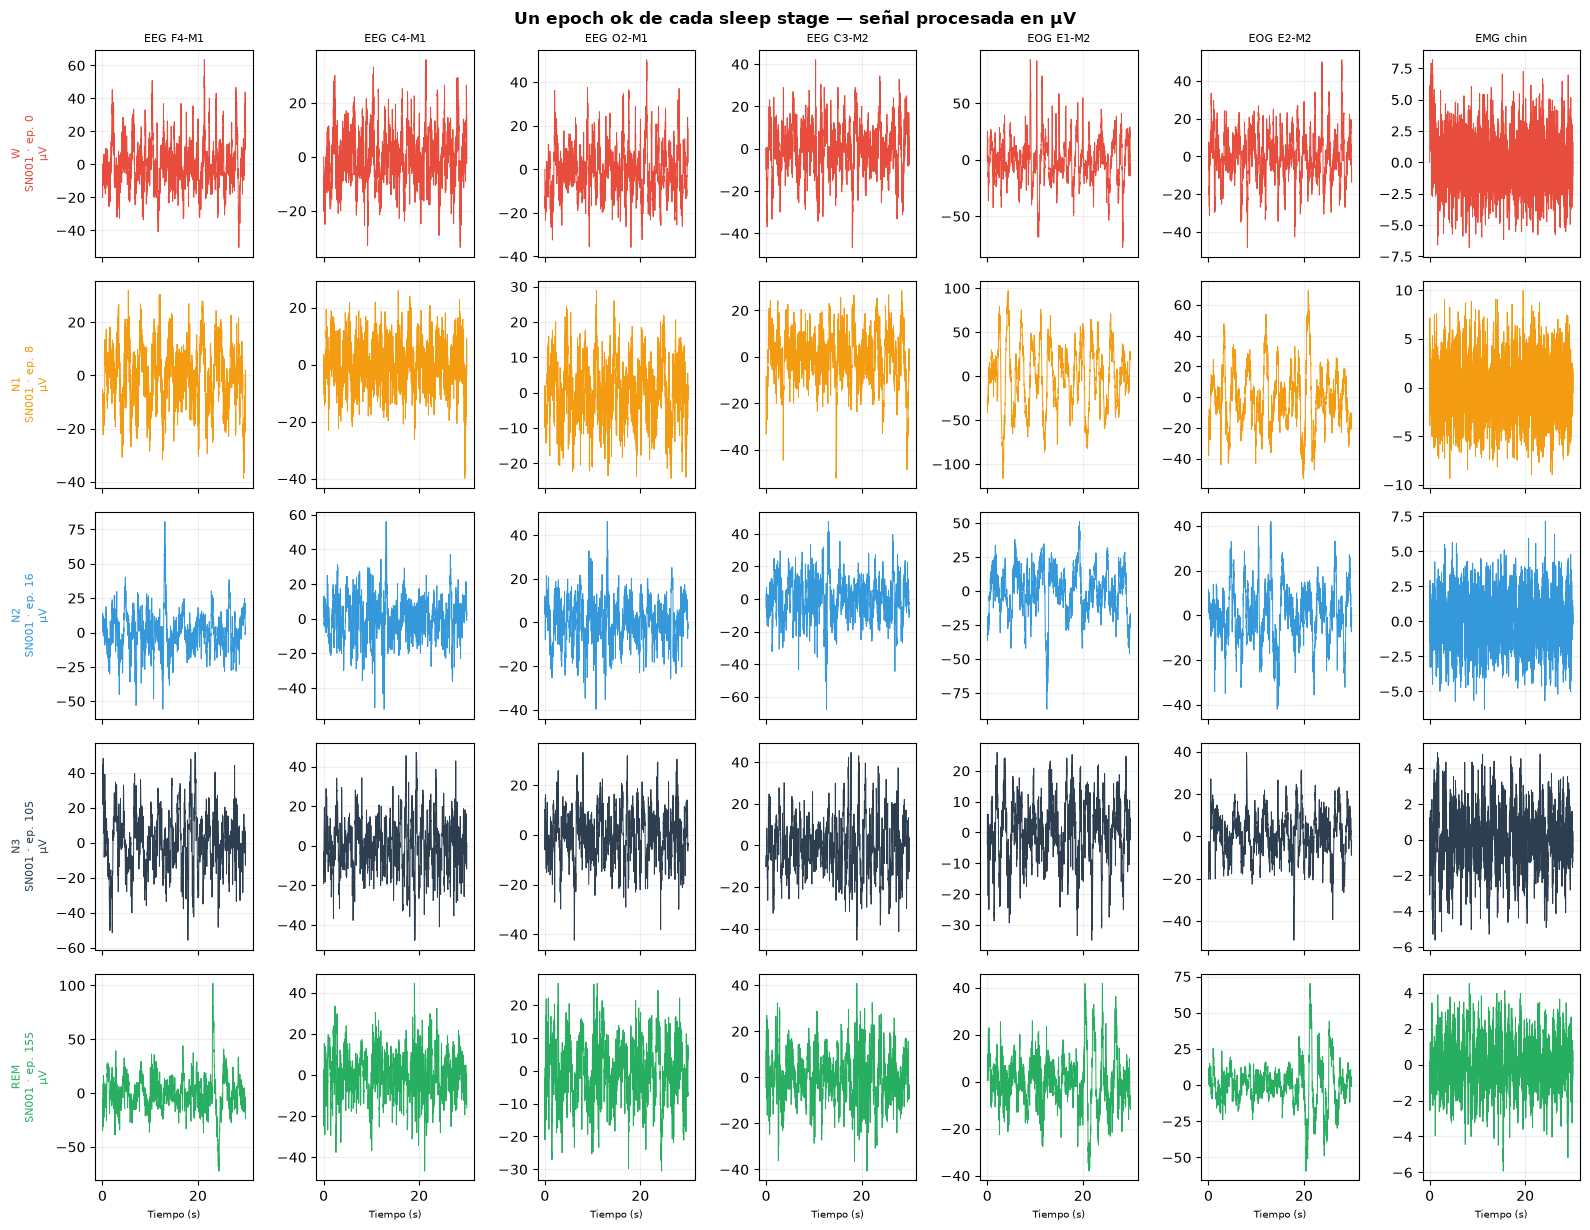

In [65]:
# ============================================================
# Mostrar un epoch ok de cada clase
# ============================================================
inv_stage_map = {
    value: key
    for key, value in STAGE_MAP.items()
}

STAGE_COLORS = {
    "Sleep stage W":  "#e74c3c",
    "Sleep stage N1": "#f39c12",
    "Sleep stage N2": "#3498db",
    "Sleep stage N3": "#2c3e50",
    "Sleep stage R":  "#27ae60",
}

processed_subjects = sorted(
    df_results.loc[df_results["status"].eq("ok"), "subject"].tolist()
)

print(f"Sujetos procesados disponibles: {len(processed_subjects)}")

representative_epochs = {}
channel_names = None
sfreq = None

for subject_id in processed_subjects:
    file_path = os.path.join(OUTPUT_PATH, f"{subject_id}.npz")
    data = np.load(file_path, allow_pickle=True)

    X_subject = data["X"]
    y_subject = data["y"]
    qc_status = data["qc_status"].astype(str)
    source_epoch_index = data["source_epoch_index"]
    recording_onset_s = data["recording_onset_s"]

    if channel_names is None:
        channel_names = list(data["channel_names"])
        sfreq = float(data["processed_sfreq"])

    ok_mask = qc_status == "ok"

    for label_int in sorted(inv_stage_map):
        if label_int in representative_epochs:
            continue

        candidate_indices = np.where(
            (y_subject == label_int) & ok_mask
        )[0]

        if len(candidate_indices) == 0:
            continue

        idx = candidate_indices[0]
        representative_epochs[label_int] = {
            "signal_uv": X_subject[idx].copy(),
            "subject": subject_id,
            "source_epoch": int(source_epoch_index[idx]),
            "onset_s": float(recording_onset_s[idx]),
        }

    if len(representative_epochs) == len(STAGE_MAP):
        break

missing_labels = [
    label_int
    for label_int in sorted(inv_stage_map)
    if label_int not in representative_epochs
]

if missing_labels:
    raise ValueError(
        "No se encontraron epochs ok para: "
        + ", ".join(inv_stage_map[label] for label in missing_labels)
    )

unique_labels = sorted(representative_epochs)
n_stages = len(unique_labels)
n_channels = len(channel_names)
n_samples = representative_epochs[unique_labels[0]]["signal_uv"].shape[1]
time_seconds = np.arange(n_samples) / sfreq

fig, axes = plt.subplots(
    n_stages,
    n_channels,
    figsize=(16, n_stages * 2.5),
    sharex=True,
)

fig.suptitle(
    "Un epoch ok de cada sleep stage — señal procesada en µV",
    fontweight="bold",
    fontsize=12,
)

for row, label_int in enumerate(unique_labels):
    stage_name = inv_stage_map[label_int]
    stage_short = STAGE_SHORT_MAP[label_int]
    color = STAGE_COLORS.get(stage_name, "gray")
    example = representative_epochs[label_int]
    epoch_signal = example["signal_uv"]

    for col, channel_name in enumerate(channel_names):
        ax = axes[row, col]
        ax.plot(time_seconds, epoch_signal[col], lw=0.7, color=color)
        ax.grid(True, alpha=0.2)

        if row == 0:
            ax.set_title(channel_name, fontsize=8)

        if col == 0:
            ax.set_ylabel(
                f"{stage_short}\n{example['subject']} · ep. {example['source_epoch']}\nµV",
                fontsize=8,
                color=color,
            )

        if row == n_stages - 1:
            ax.set_xlabel("Tiempo (s)", fontsize=7)

plt.tight_layout()
plt.show()


### Verificación visual de los epochs procesados

La visualización utiliza únicamente epochs `ok` de sujetos incluidos. Cada fila representa una etapa (`W`, `N1`, `N2`, `N3`, `REM`) y cada columna uno de los siete canales seleccionados.

La amplitud se presenta directamente en `µV`; no se aplica una escala fija de z-score. El objetivo de esta inspección es comprobar que el pipeline conserve morfologías fisiológicas plausibles después del filtrado y del resampling sin ocultar la escala original de la señal procesada.

Esta salida es la base común para las siguientes etapas:

```text
NB3 / features clásicos → usar X en µV
DL                     → normalizar X con channel_mean_uv / channel_std_uv cuando corresponda
```
